In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import muram as mio

In [2]:
path = '/dat/milic/MURaM_SSD_EN/'
num = 399000

In [3]:
snap = mio.MuramSnap(path, num)

In [5]:
snap.available

['rho',
 'vx',
 'vy',
 'vz',
 'eint',
 'Bx',
 'By',
 'Bz',
 'sflx',
 'Temp',
 'Pres',
 'ne',
 'tau']

In [6]:
# Find log tau = 0
tau_mean = np.mean(snap.tau, axis=(1, 2))
print(np.argmin(np.abs(tau_mean - 1.0)))

49


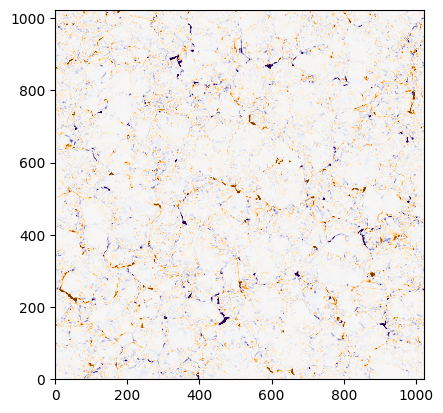

In [8]:
plt.imshow(snap.Bx[49,:,:].T * np.sqrt(4.0*np.pi), origin='lower', cmap='PuOr', vmin=-500,vmax=500)

In [18]:
# Now reconstructing from the lw synth, we need to find the problematic pixel:
task = 209
skipx = 1
skipy = 1
pixel = 1
size = 32

task_total = task * size + pixel

NX_calc = 256
NY_calc = 1024

x_calc = task_total % NX_calc
y_calc = task_total // NX_calc


print (task_total)
print (x_calc, y_calc)

# Now map back to og

x_og = x_calc * skipx + 768
y_og = y_calc * skipy

print (x_og, y_og)

6689
33 26
801 26


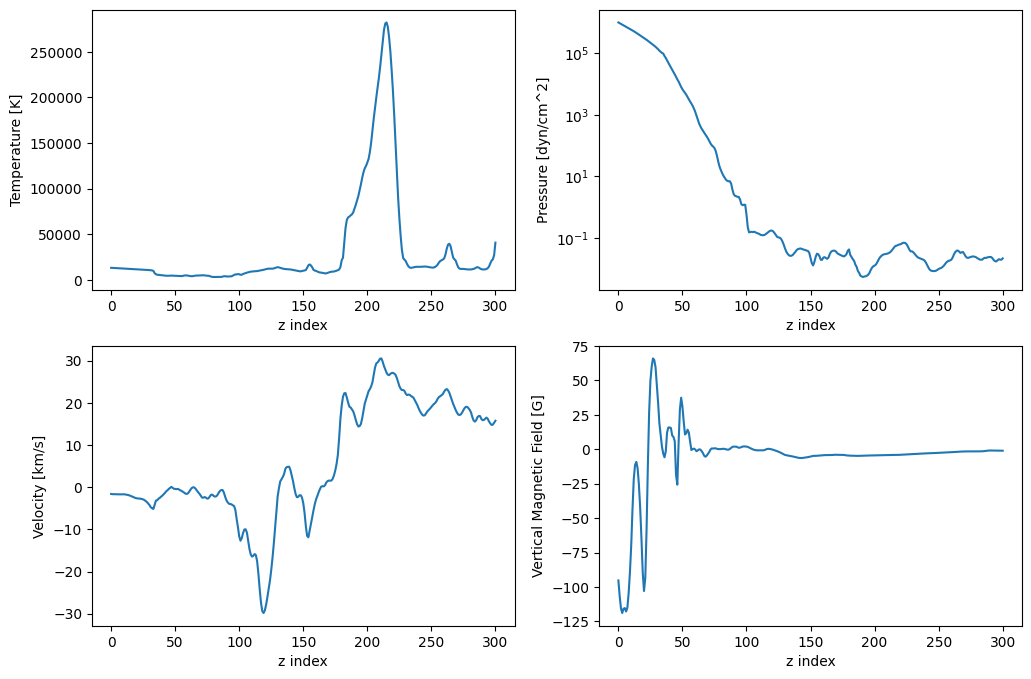

In [20]:
# Plot temperature pressure, velocity, magnetic field at that pixel:

# Range from the code:
z_min = 15
z_max = 316

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(snap.Temp[z_min:z_max, x_og, y_og])
plt.xlabel('z index')
plt.ylabel('Temperature [K]')
plt.subplot(2, 2, 2)
plt.semilogy(snap.Pres[z_min:z_max, x_og, y_og])
plt.xlabel('z index')
plt.ylabel('Pressure [dyn/cm^2]')


plt.subplot(2, 2, 3)
plt.plot(snap.vx[z_min:z_max, x_og, y_og]/-1E5)
plt.xlabel('z index')
plt.ylabel('Velocity [km/s]')

plt.subplot(2, 2, 4)
plt.plot(snap.Bx[z_min:z_max, x_og, y_og]*np.sqrt(4.0*np.pi))
plt.xlabel('z index')
plt.ylabel('Vertical Magnetic Field [G]')

plt.show()


In [ ]:
# Let's re-run the procedure and see if this one gets stuck again.